# Where does a coding ban live inside Qwen3-8B? C2d demo: a "prohibition direction" against random directions

**Artifact:** *Searching Qwen3-8B for where a coding ban lives* (`method.py`, iteration-3 internal-locus experiment).

Qwen3-8B (pinned revision `b968826d`, thinking off, T = 1.0) writes a Python program for a coding task. In the **ban**
prompt the task is preceded by a prohibition of the algorithm the model writes by default, for example
*"Do not use Dijkstra's algorithm for this task."* In its **neutral twin** the algorithm's name is replaced by an
unrelated noun and padded with `" ."`, so both prompts have the same token length and identical tokens from the task text on.
The experiment asks *where in the residual stream the prohibition lives*, with four pre-registered tests:

| Claim | Question | Full-run outcome |
|---|---|---|
| **C2d** | Is there a task-general linear "prohibition direction" `v`? Write it into the twin (**ADD**), remove it from the ban (**SUBTRACT**), and compare against norm-matched random directions under common random numbers | **DISCONFIRMED** |
| C2e | Can a decoder read, from residual states at the first generated tokens, which algorithm a banned model will write? | no locus on any testable task |
| C2f | Does mean-ablating three ban-attending heads (L21H17, L26H21, L26H25) undo the ban? | not supported |
| 0g | Do the Qwen-Scope base-model SAEs transfer to the instruct model? | pass under a lenient rule; the SAEs keep only cos ≈ 0.3 of the ban displacement |

### What this notebook runs

`method.py` orchestrates nine stages. All of them except `analyze` either run the model or need model-generated
inputs. They load Qwen3-8B with FP8 W8A8 kernels on a CUDA GPU (about 3.5 GPU-hours on a 16 GB RTX 2000 Ada), so
they cannot run on Colab. They are shown below for reference only.

This notebook runs the CPU **`analyze` stage for C2d**, through `method.py`'s own `main()`. That stage is the original
code of `src/analysis/common.py`, `src/analysis/c2d.py` and the C2d figure panels of `src/analysis/run_all.py`. Its
input is `mini_demo_data.json`, which holds 100 **common-random-number (CRN) slots** from the run's `c2d_arms` output.
A slot is one (task, template, k) triple, and it records the labelled program that every arm wrote from the same
random numbers. The slots cover two tasks:

- **T2**: shortest path in a weighted directed graph (default: **Dijkstra**)
- **T03**: the k-th smallest value of a list (default: **full sort**)

Each task contributes the 5 ban templates W1–W5 × slots k = 0–9, which are the slots on which every arm was sampled
(including all 18 random-direction arms). The ADD-versus-random tests computed here therefore use exactly the
full run's data.

The whole notebook runs in about a minute on a CPU; most of that is installing packages.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru -- NOT pre-installed on Colab, always install (the version pinned in the artifact's pyproject.toml)
_pip('loguru==0.7.3')

# numpy, scipy, matplotlib -- pre-installed on Colab, install locally only (at Colab's exact versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'matplotlib==3.10.0')

In [2]:
from __future__ import annotations

# --- method.py (original import block) ---
import argparse
import sys
import time
from pathlib import Path

from loguru import logger  # noqa: E402

# method.py also runs `ROOT = Path(__file__).resolve().parent`, `sys.path.insert(0, str(ROOT / "src"))` and
# `from cfg import (RESULTS_DIR, SAMPLED_TASKS, read_json, read_jsonl, set_ram_limit, setup_logging, utc_now,
# write_json)`. A notebook has no __file__ and no src/ package, so those cfg names are defined in a cell below.

# --- src/cfg.py ---
import hashlib
import json
import math
import os
import resource
from datetime import datetime, timezone
from typing import Any, Iterable

# --- src/analysis/common.py, src/analysis/c2d.py, src/analysis/run_all.py ---
import re
from collections import Counter

import numpy as np
from scipy.stats import binom

# --- notebook additions: inline figures and the results plots ---
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

plt.rcParams["figure.dpi"] = 110  # notebook: sharper inline figures (the original only saves PNG/PDF files)

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_5eGZGmskluur/round-3/experiment-17/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()

examples = data["datasets"][0]["examples"]
print(f"{len(examples)} CRN slots in dataset '{data['datasets'][0]['dataset']}': "
      f"tasks {sorted({e['metadata_task'] for e in examples})}, templates {sorted({e['metadata_template'] for e in examples})}, "
      f"k {min(e['metadata_k'] for e in examples)}-{max(e['metadata_k'] for e in examples)}")
# one slot: the ban prompt, then the label|pass of the program each arm wrote with the same random numbers
ex0 = next(e for e in examples if e["metadata_task"] == "T2")
print("\n" + ex0["input"][:330] + " ...\n")
for k in ("predict_NEUTRAL", "predict_BAN", "predict_ADD_a1p0", "predict_RAND9001_a1p0", "predict_SUB_plain"):
    print(f"  {k:<24}{ex0[k]}")
print(f"  ... {sum(k.startswith('predict_') for k in ex0)} arms on this slot")

100 CRN slots in dataset 'c2d_arms': tasks ['T03', 'T2'], templates ['W1', 'W2', 'W3', 'W4', 'W5'], k 0-9

task=T2 template=W1 slot k=0. Ban prompt: Do not use Dijkstra's algorithm for this task.

Task: write a Python function solve(n, edges, s, t) that returns the length of the shortest path from node s to node t in a directed weighted graph. Nodes are numbered 0 to n-1 with 1 <= n <= 100. edges is a list of (u, v, w) tuples, each a ...

  predict_NEUTRAL         dijkstra|pass
  predict_BAN             bf_spfa|pass
  predict_ADD_a1p0        bf_spfa|fail
  predict_RAND9001_a1p0   dijkstra|pass
  predict_SUB_plain       bf_spfa|pass
  ... 26 arms on this slot


## Configuration

These are all the tunable parameters of the demo, and the comment on each line gives the original value:

- `STAGE` selects the `method.py` stage to run. Only `"analyze"` runs here.
- `DEMO_TASKS` and `SLOTS_PER_TEMPLATE` select which of the demo file's slots are analysed. At 2 tasks × k 0–9, the
  file is used in full.
- The three resample counts are the bootstrap and permutation sizes hard-coded in `src/analysis/common.py` and
  `src/analysis/c2d.py`. At their original values the analysis still takes well under a second.

The full run analysed 6 tasks. BAN, NEUTRAL, SUB_plain and ADD α = 1 were sampled on slots k = 0–19 (k = 0–79 for
T1/W4); every other arm used k = 0–9.

In [5]:
STAGE = "analyze"            # method.py stage to run. Only "analyze" (CPU) can run here; prompts / gpu1 / label /
                             # commit2 / gpu2 / s8c / gpu3 / c2e / zerog need the full repository, Qwen3-8B and a GPU
DEMO_TASKS = ("T2", "T03")   # tasks to analyse; the demo file holds T2 and T03 (full run: T2, T1, T03, T04, T06, T05)
SLOTS_PER_TEMPLATE = 10      # analyse CRN slots k = 0 .. SLOTS_PER_TEMPLATE-1 of each template W1-W5 (demo file: k 0-9)
N_BOOT_SLOTS = 2000          # paired slot bootstrap of each SUBTRACT delta     (original: 2000, boot_mean_diff)
N_JS_PERM = 1000             # within-template permutation null of the JS test   (original: 1000, js_null)
N_BOOT_TASKS = 5000          # task bootstrap of the pooled SUBTRACT delta        (original: 5000, run_c2d)

## 1. The pipeline (`method.py`) and its shared constants (`src/cfg.py`)

`method.py` is a resumable stage orchestrator. Its module docstring lists the stages:

```
prompts   S1 (CPU)                     ban prompts + token-aligned neutral twins, 14 tasks x W1-W5
gpu1      S2 + GPU unit tests + commit #1 + U7 + S5 (ban-free arms) + C2f head means
label     label worker (CPU): labels every raw sample as it appears (exp8 suite for T1/T2, exp11 bench label_one)
commit2   S6 (CPU): S5 summaries, ADD-landing forecast, commit #2
gpu2      S7 (ban arms, SUB, heads, W4 top-up) + S8 state extraction
zerog     0g SAE transfer (GPU, base model in a separate load)
analyze   S9 analyses (C2d, C2e, C2f, 0g report, 5a, 5c) + figures + method_out.json
```

How C2d's arms are built. Every edit acts on the prompt *prefill* only, at the task-spec positions S
(from `Task:` to the end of the user message) of blocks 12–23. Generation is then sampled with no edit.

- **Direction `v`.** Take the displacement `d = h_ban − h_twin` at every position in S, for each of 14 tasks ×
  5 templates. For each sampled task, `v` is the mean of `d` over the **13 other** tasks (leave-one-task-out). It
  never sees the held-out task's banned algorithm X, which is what "X-free" means. `n[l, p]` is the task's own
  mean ban-displacement norm at block l, position p.
- **NEUTRAL** is the twin prompt and **BAN** the named ban.
- **ADD_aα** takes the twin prompt and sets its displacement along `v̂` to exactly α·n[l, p] at every hooked block.
  It asks whether `v` is *sufficient* to produce the ban.
- **RAND<seed>_aα** is the same edit along a random unit direction with the same norm. Seeds 9001–9003 are the
  frozen controls; 9004–9015 are exploratory.
- **SUB_plain** projects `v̂` out of the ban prompt. It asks whether `v` is *necessary* for the ban.
  **SUB_affine** removes only the ban's excess over the twin along `v̂`. **SUB_rand9001** applies a random edit of
  SUB_plain's norm.
- **CRN slot** (task, template, k): every arm uses the same uniforms of the inverse-CDF sampler on a slot. So two arms
  differ on a slot only because of their prompt or edit, which is why exact paired (McNemar) tests apply.

The next cell holds the parts of `src/cfg.py` that `method.py` and the C2d analysis import:
- paths
- the model constants
- tasks and their default algorithms
- the ban templates W1–W5
- the design constants
- the small I/O and statistics utilities

In [6]:
# ---- src/cfg.py (excerpt: every name that method.py and the C2d analysis import) ---------------------------------
ROOT = Path.cwd()  # cfg.py: Path(__file__).resolve().parents[1], the artifact folder (a notebook has no __file__)
INPUTS = ROOT / "inputs"
E8 = INPUTS / "exp8"
E11 = INPUTS / "exp11"
E12 = INPUTS / "exp12"
E9 = INPUTS / "exp9"
E7 = INPUTS / "exp7"
BENCH = E11 / "bench"
SUITE = E8 / "suite"
PROMPTS_DIR = ROOT / "prompts"
DATA_DIR = ROOT / "data"
TOKEN_DIR = DATA_DIR / "token_ids"
RESULTS_DIR = ROOT / "results"
FIG_DIR = ROOT / "figures"
LOG_DIR = ROOT / "logs"
DIR_DIR = ROOT / "directions"
STATES_DIR = ROOT / "states"
PRED_DIR = ROOT / "predictions"
# cfg.py creates every one of these folders at import time. The demo leaves that loop out: it writes only
# results/c2d.json and logs/analyze.log, and write_json() and the loguru file sink create those folders themselves.

# ------------------------------------------------------------------------------------------------ model
MODEL_ID = "Qwen/Qwen3-8B"
MODEL_REVISION = "b968826d9c46dd6066d109eabc6255188de91218"
BASE_MODEL_ID = "Qwen/Qwen3-8B-Base"
SAE_REPO = "Qwen/SAE-Res-Qwen3-8B-Base-W64K-L0_50"
N_LAYERS = 36
D_MODEL = 4096
N_HEADS = 32
HEAD_DIM = 128
IM_END = 151645
ENDOFTEXT = 151643
MAX_NEW_TOKENS = 1024
TEMPERATURE = 1.0
DECODING = "T1.0_topp1.0_topk-off_max1024_thinkoff"
TEMPLATE_TAIL = "<|im_end|>\n<|im_start|>assistant\n<think>\n\n</think>\n\n"
# Quantisation actually used (deviation F2; the 16 GB RTX 2000 Ada cannot hold the 16.4 GB of bf16 weights):
QUANT = "fp8_e4m3_w8a8_dynamic(per-output-channel weight scales, per-token activation scales; lm_head/embeddings/norms bf16)"
# (model_path(), which finds the pinned snapshot in HF_HUB_CACHE for the GPU engine, is left out)

# ------------------------------------------------------------------------------------------------ tasks
PATH_TASKS = ("T1", "T2")
BENCH_TASKS = ("T03", "T04", "T06", "T05", "T10", "R1", "T08", "R3", "T13", "R6", "T14", "T11")
ALL_TASKS = PATH_TASKS + BENCH_TASKS  # 14 tasks: the direction is built from all of them
SAMPLED_TASKS = ("T2", "T1", "T03", "T04", "T06", "T05")  # sampling order (fallback F3: whole tasks in this order)
DEFAULT = {"T1": "bfs", "T2": "dijkstra", "T03": "full_sort", "T04": "naive", "T06": "hash_set", "T05": "hash_map",
           "T10": "union_find", "R1": "greedy_end", "T08": "iteration", "R3": "kahn", "T13": "sort_sweep",
           "R6": "binary_search", "T14": "sort_by_count", "T11": "quadratic_dp"}
EXP8_TASK = {"T1": "t1", "T2": "t2"}
TEMPLATES: dict[str, tuple[str, str]] = {  # (ban, neutral) -- protocol v2 W1-W5, verbatim
    "W1": ("Do not use {X} for this task.", "Do not use {N} for this task."),
    "W2": ("Your solution must not rely on {X}.", "Your solution must not rely on {N}."),
    "W3": ("Avoid {X} entirely.", "Avoid {N} entirely."),
    "W4": ("{X} is not allowed here.", "{N} is not allowed here."),
    "W5": ("Write a correct solution that does not use {X}.", "Write a correct solution that does not use {N}."),
}
TEMPLATE_IDS = list(TEMPLATES)
PAD_FILLER = " ."  # exp7 frozen padding rule: neutral segment + d x ' .' so the twin has the ban's token length

# ------------------------------------------------------------------------------------------------ design
V_BLOCKS = list(range(12, 24))          # blocks whose outputs are edited (exp8 band B2)
SAVE_BLOCKS = list(range(8, 29))        # blocks saved for diagnostics / decoders
ALPHAS_ADD = (1.0, 2.0, 0.5)
ALPHAS_RAND = (1.0, 2.0)
RAND_SEEDS = (9001, 9002, 9003)
HEAD_TARGET = [(21, 17), (26, 21), (26, 25)]
HEAD_RAND_SEEDS = (7101, 7102, 7103)
N_PER_TEMPLATE_FULL = 20                # k 0-19 x 5 templates = 100
N_PER_TEMPLATE_HALF = 10                # k 0-9 x 5 templates = 50
BATCH = 20                              # every sampled batch has exactly 20 rows (two 10-slot blocks or one 20-slot)
GEN_POSITIONS = [1, 2, 3, 4, 5, 6, 7, 8, 16]
JUDGE_CAP_USD = 0.40  # raised from the plan's 0.20 (logged deviation): T2 ban programs often leave runtime+AST unresolved
BUDGET_MSG = "AI Inventor per-run OpenRouter budget"


# ------------------------------------------------------------------------------------------------ utils
# (container_ram_gb, detect_cpus, the sha256 helpers, stable_seed, append_jsonl, write_jsonl, cap_first and rel are
#  used only by the GPU and labelling stages and are left out)
def setup_logging(name: str) -> None:
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    logger.add(str(LOG_DIR / f"{name}.log"), rotation="30 MB", level="DEBUG")


def set_ram_limit(gb: float) -> None:
    lim = int(gb * 1024 ** 3)
    try:
        resource.setrlimit(resource.RLIMIT_AS, (lim, lim))
    except (ValueError, OSError) as e:
        logger.warning(f"could not set RLIMIT_AS: {e}")


def utc_now() -> str:
    return datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%S.%fZ")


def read_jsonl(p: Path) -> list[dict[str, Any]]:
    p = Path(p)
    if not p.exists():
        return []
    out = []
    with open(p) as fh:
        for line in fh:
            line = line.strip()
            if line:
                try:
                    out.append(json.loads(line))
                except json.JSONDecodeError:
                    logger.warning(f"skipping malformed line in {p.name}")
    return out


def _json_default(o: Any) -> Any:
    import numpy as np

    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return None if not np.isfinite(o) else float(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, Path):
        return str(o)
    if isinstance(o, (set, frozenset)):
        return sorted(o)
    raise TypeError(f"not JSON serialisable: {type(o)}")


def _finite(o: Any) -> Any:
    if isinstance(o, float):
        return o if math.isfinite(o) else None
    if isinstance(o, dict):
        return {str(k): _finite(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [_finite(v) for v in o]
    return o


def write_json(p: Path, obj: Any, indent: int | None = 1) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(p.suffix + ".tmp")
    tmp.write_text(json.dumps(_finite(json.loads(json.dumps(obj, default=_json_default))), indent=indent))
    tmp.replace(p)


def read_json(p: Path) -> Any:
    return json.loads(Path(p).read_text())


def wilson_ci(k: int, n: int, z: float = 1.959963984540054) -> tuple[float, float]:
    if n == 0:
        return (float("nan"), float("nan"))
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (max(0.0, c - h), min(1.0, c + h))

### The GPU stages of `method.py` (defined for reference, not run here)

These are `method.py`'s stage functions, unchanged. Each one imports the FP8 engine (`engine.load_model`), the CRN
sampler, the hooks or the state extractor from the artifact's `src/` package, and needs Qwen3-8B on a CUDA GPU with
FP8 support (compute capability ≥ 8.9, ≥ 16 GB). Defining them here is harmless, because all of their imports sit
inside the function bodies. With `STAGE = "analyze"` they are never called.

- `gpu1`: builds the direction `v` (S2), runs the GPU unit tests and hash-commits the decision rules (commit #1).
  It then validates the engine against exp8 (U7: T2 ban 2/20 Dijkstra, twin 20/20) and samples the ban-free arms
  (NEUTRAL, ADD, RAND) of every task.
- `s8c`: re-extracts teacher-forced states at batch 1 for the descriptive geometry analysis (5c).
- `u1b`: determinism unit test. Decoding is independent of row position, so CRN coupling is exact. Teacher
  forcing is bit-exact at batch 1 but not in 20-row FP8 batches.
- `gpu3`: exploratory stage. It samples 12 extra random directions on T2/T1/T03 and runs the C2e extension to
  generated positions 24–96.
- `c2e_stage`: the C2e within-ban locus decoders (GPU IRLS).

The ban-condition arms (BAN, SUB_*, HEADS_*) are sampled later, by `src/gpu2.py`, after commit #2.

In [7]:
# ---- method.py: GPU stages (unchanged; defined but not called in this notebook) ---------------------------------
def gpu1(deadline: float, optional_until: float) -> None:
    import torch

    from direction import stage_direction
    from engine import load_model
    from gpu_tests import run_gpu_tests
    from prereg import write_commit1
    from prompts import load_prompts
    from sampling import TaskContext, run_batch, run_task_phase, s5_batches

    torch.cuda.set_per_process_memory_fraction(0.97, 0)
    tok, model = load_model()
    prompts = load_prompts()
    if not (RESULTS_DIR / "direction.json").exists():
        stage_direction(model)
    if not (RESULTS_DIR / "unit_tests_gpu.json").exists():
        res = run_gpu_tests(model, tok, prompts)
        if not res["all_pass"]:
            logger.error("GPU unit tests failed -- see results/unit_tests_gpu.json")
            raise SystemExit(2)
    if not (ROOT / "predictions" / "commit1.json").exists():
        c = write_commit1()
        logger.info(f"commit #1: {len(c['chain'])} files hash-chained")
    # U7 engine validation against exp8 (T2, exp8 frozen prompts and exp8 uniform keys ('beh', 't2', w, s))
    raw = read_jsonl(ROOT / "data" / "samples_raw.jsonl")
    if not any(r.get("block_id", "").startswith("U7") for r in raw):
        ctx = TaskContext(model, tok, prompts, "T2")
        for arm in ("BAN", "NEUTRAL"):
            rows = run_batch(ctx, "W1", [(arm, list(range(20)))], f"U7:T2:W1:{arm}", ukey=("beh", "t2"),
                             arm_prefix="U7_")
            logger.info(f"U7 {arm}: {len(rows)} rows sampled with exp8 keys")
    # S5 required arms, whole tasks in the frozen order
    for t in SAMPLED_TASKS:
        n = run_task_phase(model, tok, prompts, t, s5_batches(), "S5", deadline=deadline)
        logger.info(f"S5 {t}: {n} new batches")
    # optional S5 arms (RAND alpha 2 for seeds 9002/9003, then ADD alpha 0.5) while time allows
    for t in SAMPLED_TASKS:
        if time.time() > optional_until:
            break
        run_task_phase(model, tok, prompts, t, s5_batches(optional=True), "S5", deadline=optional_until)
    write_json(RESULTS_DIR / "gpu1_done.json", {"utc": utc_now()})


EXTRA_SEEDS = list(range(9004, 9016))


def s8c() -> None:
    """Re-extract the 5c states of every non-ban/neutral arm at batch 1, so all 5c points share one extraction mode
    (BAN/NEUTRAL were re-extracted at batch 1 in gpu3; mixing batch-20 and batch-1 states would add a systematic
    row-position offset between arms)."""
    from engine import load_model
    from gpu2 import _raw_by_arm
    from prompts import load_prompts
    from states import BLOCKS_5C, save_arm

    tok, model = load_model()
    prompts = load_prompts()
    t0 = time.time()
    for (t, arm), rows in sorted(_raw_by_arm().items()):
        if t not in SAMPLED_TASKS or arm in ("BAN", "NEUTRAL", "BAN_TOPUP") or arm.startswith(("U7", "RAND90")) \
                and arm not in ("RAND9001_a1.0", "RAND9002_a1.0", "RAND9003_a1.0", "RAND9001_a2.0", "RAND9002_a2.0",
                                "RAND9003_a2.0"):
            continue
        kind = "twin" if (arm.startswith("ADD") or arm.startswith("RAND")) else "ban"
        save_arm(model, prompts, t, arm, rows, tag=f"5c_{t}_{arm}", blocks=BLOCKS_5C, full=False, prompt_kind=kind,
                 bs=1, overwrite=True)
    write_json(RESULTS_DIR / "s8c_done.json", {"utc": utc_now(), "seconds": time.time() - t0})


def u1b(model, tok, prompts) -> None:
    """U1b: (a) decode is row-position independent: rows with identical prefill and identical uniforms placed at
    different batch positions give identical tokens; (b) teacher forcing at batch 1 is deterministic and depends only on
    the prefix; (c) teacher forcing in a 20-row batch is NOT (FP8 GEMM tiling), quantified."""
    import numpy as np

    from engine import forward_capture, sample, u_stream
    from sampling import TaskContext

    ctx = TaskContext(model, tok, prompts, "T2")
    pre = ctx.clean_prefill("W1", "twin")["pre"]
    us = [u_stream("u1b", j % 10) for j in range(20)]  # row j and row j+10 share uniforms
    res = sample(model, [{"pre": pre, "us": us}], max_new=96)
    same = [res[j]["token_ids"] == res[j + 10]["token_ids"] for j in range(10)]
    pr = prompts[("T2", "W1", "ban")]
    ids = pr["ids"] + [73594, 12669, 198]
    P = pr["P"]
    a = forward_capture(model, [ids], [20, 28], [P - 1, P])
    b = forward_capture(model, [ids], [20, 28], [P - 1, P])
    batch = forward_capture(model, [ids] * 20, [20, 28], [P - 1, P])
    d1 = float((a["states"][28] - b["states"][28]).abs().max())
    xs = batch["states"][28]
    rel = float(((xs - xs[0:1]).norm(dim=-1) / xs[0:1].norm(dim=-1)).max())
    rel_b1_vs_batch = float(((xs - a["states"][28]).norm(dim=-1) / a["states"][28].norm(dim=-1)).max())
    out = {"decode_rows_identical_given_same_uniforms": all(same), "n_pairs": len(same),
           "batch1_repeat_max_abs_diff_block28": d1,
           "batch20_identical_rows_max_rel_l2_diff_block28": rel,
           "batch20_vs_batch1_max_rel_l2_diff_block28": rel_b1_vs_batch,
           "note": "(a) decode at M=20 is position independent, so CRN coupling across arms is exact; (b)/(c) teacher "
                   "forcing must run at batch 1 for states to depend only on the prefix"}
    write_json(RESULTS_DIR / "unit_tests_u1b.json", out)
    logger.info(f"U1b: {out}")


def gpu3(deadline: float) -> None:
    """EXPLORATORY (not in the frozen rules): 12 more random directions at alpha 1 on T2, T1, T03 -- where does ADD's
    avoidance sit in the distribution of random-direction effects? Same construction, CRN slots k 0-9."""
    import torch

    from engine import load_model
    from prompts import load_prompts
    from sampling import K10, run_task_phase

    tok, model = load_model()
    prompts = load_prompts()
    if not (RESULTS_DIR / "unit_tests_u1b.json").exists():
        u1b(model, tok, prompts)
    # S8 re-extraction at batch 1 (the plan's specification; see unit_tests_u1b.json and README)
    if not (RESULTS_DIR / "s8_batch1_done.json").exists():
        from gpu2 import _raw_by_arm
        from states import stage_states_b1

        stage_states_b1(model, prompts, _raw_by_arm(), list(SAMPLED_TASKS))
        write_json(RESULTS_DIR / "s8_batch1_done.json", {"utc": utc_now()})
    # conditional causal patch (9.2): only for tasks where C2e found a locus (k*, L*)
    c2e_p = RESULTS_DIR / "c2e.json"
    if c2e_p.exists():
        from patch import analyse_patch, run_patch

        for t, v in read_json(c2e_p)["primary"].items():
            if v.get("locus") and not (RESULTS_DIR / f"c2e_patch_{t}.json").exists():
                run_patch(model, tok, prompts, t, v["locus"]["k"], v["locus"]["block"])
                analyse_patch(t)
    # exploratory C2e extension: states at generated positions 24-96 (the frozen window ends before the fork)
    from c2e_ext import extract, run_all_ext

    try:
        extract(model, prompts)
    except Exception as e:  # noqa: BLE001 - exploratory; never block the remaining stage
        logger.exception(f"C2e extension extraction failed: {e}")
    batches = [[(f"RAND{a}_a1.0", K10), (f"RAND{b}_a1.0", K10)] for a, b in zip(EXTRA_SEEDS[::2], EXTRA_SEEDS[1::2])]
    for t in ("T2", "T1", "T03"):
        if time.time() > deadline:
            break
        n = run_task_phase(model, tok, prompts, t, batches, "X1", deadline=deadline)
        logger.info(f"X1 extra random directions {t}: {n} batches")
    torch.cuda.empty_cache()
    try:
        if not (RESULTS_DIR / "c2e_extension.json").exists():
            run_all_ext()
    except Exception as e:  # noqa: BLE001
        logger.exception(f"C2e extension decoders failed: {e}")
    write_json(RESULTS_DIR / "gpu3_done.json", {"utc": utc_now()})


def c2e_stage(deadline: float) -> None:
    """9.2 C2e decoders on the GPU (primary per sampled task; secondary archive-pooled analysis for T1/T2)."""
    from analysis.c2e import run_task

    out_p = RESULTS_DIR / "c2e.json"
    res = read_json(out_p) if out_p.exists() else {"primary": {}, "secondary_archive_pooled": {}}
    for t in SAMPLED_TASKS:
        if t in res["primary"] or time.time() > deadline:
            continue
        t0 = time.time()
        res["primary"][t] = run_task(t, n_perm=500 if t in ("T1", "T2") else 200)
        res["primary"][t]["seconds"] = time.time() - t0
        write_json(out_p, res)
        logger.info(f"C2e {t}: {res['primary'][t].get('status')} locus={res['primary'][t].get('locus')} "
                    f"({time.time() - t0:.0f}s)")
    for t in ("T1", "T2"):
        if t in res["secondary_archive_pooled"] or time.time() > deadline:
            continue
        r = run_task(t, n_perm=200, archive=True)
        r["label"] = "secondary, archive-pooled (exp8 arm a + exp12 fresh pool; blocks 8-28 every 2nd block)"
        res["secondary_archive_pooled"][t] = r
        write_json(out_p, res)
    res["n_perm"] = {"T1": 500, "T2": 500, "bench": 200, "archive": 200}
    write_json(out_p, res)

## 2. Labelled sample rows and the paired statistics (`src/analysis/common.py`)

In the full run, `merged()` joins `data/samples_raw.jsonl` with `data/labels.jsonl`. The first file holds every
generated program (task, template, arm, slot); the second holds its label. Labels are mechanism-level: a runtime
trace decides first, the AST second, and a blind LLM judge only when those two disagree. So a renamed or disguised
Dijkstra still counts as Dijkstra.

**The one change in this cell** is that `merged()` rebuilds the same rows from the demo data: each
`predict_<arm> = "<label>|<pass|fail>"` entry of a slot becomes one row. The reconstruction was checked against the
full run. Rebuilt from all 660 slots of `c2d_arms`, these rows reproduce every share, test, bootstrap CI and verdict
in the artifact's `results/c2d.json`. The exceptions are the realised edit norms (a separate file) and the
descriptive shares of the head-ablation arms (a separate dataset).

The other helpers are unchanged:
- `shares()`: avoidance = 1 − default share, over *attempted* programs only (`invalid` and `disputed` are excluded).
  It also returns a Wilson CI, the landing distribution of the non-default programs and their modal landing.
- `paired()` / `by_slot()`: pair two arms on their common CRN slots.
- `mcnemar_one_sided()`: exact one-sided McNemar test on the discordant pairs. n10 counts slots where arm A avoided
  the default and arm B did not; n01 counts the reverse.
- `holm()`: Holm correction.
- `boot_mean_diff()`: paired slot bootstrap. Its resample count now defaults to `N_BOOT_SLOTS`.
- `js_divergence()`: Jensen–Shannon divergence in bits.

In [8]:
# ---- src/analysis/common.py: shared analysis helpers (merged sample rows, behaviour shares, exact paired tests,
# Holm, bootstraps) -------------------------------------------------------------------------------------------------
RAW = DATA_DIR / "samples_raw.jsonl"      # full run only: every generated sample (not part of the demo data)
LABELS = DATA_DIR / "labels.jsonl"        # full run only: one label row per sample (not part of the demo data)
NOT_ATTEMPTED = ("invalid", "disputed")


def merged(drop_text: bool = True) -> list[dict[str, Any]]:
    """DEMO VERSION. The original joins data/samples_raw.jsonl with data/labels.jsonl:

        labs = {r["key"]: r for r in read_jsonl(LABELS)}
        for r in read_jsonl(RAW): row = r without text / token_ids, + label, passed, valid, ... and is_default

    Here the same rows are rebuilt from the demo data: one c2d_arms example per CRN slot (task, template, k), whose
    predict_<arm> = '<label>|<pass|fail>' entries become one row each (the inverse of run_all.method_out)."""
    out = []
    for e in data["datasets"][0]["examples"]:
        if e["metadata_task"] not in DEMO_TASKS or e["metadata_k"] >= SLOTS_PER_TEMPLATE:
            continue
        for col, v in e.items():
            if not col.startswith("predict_"):
                continue
            label, pf = v.split("|")
            # undo run_all._san(): 'ADD_a1p0' -> 'ADD_a1.0', 'RAND9001_a2p0' -> 'RAND9001_a2.0'
            arm = re.sub(r"_a(\d+)p(\d+)$", r"_a\1.\2", col[len("predict_"):])
            row = {"task": e["metadata_task"], "template": e["metadata_template"], "arm": arm,
                   "sample_id": e["metadata_k"]}
            row["key"] = f"{row['task']}|{row['template']}|{row['arm']}|{row['sample_id']}"
            row["label"] = label
            row["passed"] = pf == "pass"
            row["is_default"] = label == DEFAULT[row["task"]]
            out.append(row)
    return out


def rows_of(rows: list[dict[str, Any]], task: str, arm: str, ks: list[int] | None = None) -> list[dict[str, Any]]:
    return [r for r in rows if r["task"] == task and r["arm"] == arm and "label" in r
            and (ks is None or int(r["sample_id"]) in ks)]


def shares(rows: list[dict[str, Any]], task: str, disputed_as_default: bool = False) -> dict[str, Any]:
    """Behaviour summary of a set of labelled rows of one task."""
    x = DEFAULT[task]
    labs = []
    for r in rows:
        l = r["label"]
        if l == "disputed" and disputed_as_default:
            l = x
        labs.append(l)
    att = [l for l in labs if l not in NOT_ATTEMPTED]
    n_att = len(att)
    n_def = sum(l == x for l in att)
    nondef = [l for l in att if l != x]
    land = Counter(nondef)
    corr = Counter(r["label"] for r in rows if r["label"] not in NOT_ATTEMPTED and r["label"] != x and r.get("passed"))
    n = len(rows)
    av = 1 - n_def / n_att if n_att else float("nan")
    lo, hi = wilson_ci(n_att - n_def, n_att) if n_att else (float("nan"), float("nan"))
    modal = land.most_common(1)[0][0] if land else None
    pc = np.array(list(corr.values()), float)
    hill_cc = float(math.exp(-(pc / pc.sum() * np.log(pc / pc.sum())).sum())) if pc.sum() > 0 else 0.0
    return {"n": n, "n_attempted": n_att, "n_default": n_def, "n_nondefault": len(nondef),
            "avoidance": av, "avoidance_ci95": [lo, hi], "default_share": (n_def / n_att) if n_att else float("nan"),
            "landing": dict(land.most_common()), "modal_nondefault": modal,
            "modal_nondefault_n": land.most_common(1)[0][1] if land else 0,
            "landing_correct_only": dict(corr.most_common()), "hill_cc": hill_cc,
            "pass_rate": float(np.mean([bool(r.get("passed")) for r in rows])) if n else float("nan"),
            "other_share": (sum(l == "other" for l in labs) / n) if n else float("nan"),
            "invalid_share": (sum(l == "invalid" for l in labs) / n) if n else float("nan"),
            "disputed_share": (sum(l == "disputed" for l in labs) / n) if n else float("nan")}


def by_slot(rows: list[dict[str, Any]]) -> dict[tuple[str, int], dict[str, Any]]:
    return {(r["template"], int(r["sample_id"])): r for r in rows}


def avoided(r: dict[str, Any]) -> int | None:
    """1 = attempted and non-default, 0 = default, None = not attempted (invalid / disputed)."""
    if r["label"] in NOT_ATTEMPTED:
        return None
    return int(r["label"] != DEFAULT[r["task"]])


def mcnemar_one_sided(a: list[int], b: list[int]) -> dict[str, Any]:
    """Exact one-sided McNemar on paired binary outcomes: H1 P(a=1,b=0) > P(a=0,b=1)."""
    n10 = sum(1 for x, y in zip(a, b) if x == 1 and y == 0)
    n01 = sum(1 for x, y in zip(a, b) if x == 0 and y == 1)
    n = n10 + n01
    p = float(binom.sf(n10 - 1, n, 0.5)) if n > 0 else 1.0
    return {"n10": n10, "n01": n01, "n_pairs": len(a), "p_one_sided": p}


def mcnemar_two_sided(a: list[int], b: list[int]) -> dict[str, Any]:
    n10 = sum(1 for x, y in zip(a, b) if x == 1 and y == 0)
    n01 = sum(1 for x, y in zip(a, b) if x == 0 and y == 1)
    n = n10 + n01
    p = float(min(1.0, 2 * binom.cdf(min(n10, n01), n, 0.5))) if n > 0 else 1.0
    return {"n10": n10, "n01": n01, "n_pairs": len(a), "p_two_sided": p}


def holm(ps: list[float]) -> list[float]:
    m = len(ps)
    order = np.argsort(ps)
    adj = [0.0] * m
    run = 0.0
    for rank, i in enumerate(order):
        v = min(1.0, (m - rank) * ps[i])
        run = max(run, v)
        adj[i] = run
    return adj


def paired(rows_a: list[dict[str, Any]], rows_b: list[dict[str, Any]], fn=avoided) -> tuple[list[int], list[int]]:
    A, B = by_slot(rows_a), by_slot(rows_b)
    xs, ys = [], []
    for s in sorted(set(A) & set(B)):
        x, y = fn(A[s]), fn(B[s])
        if x is None or y is None:
            continue
        xs.append(x)
        ys.append(y)
    return xs, ys


def boot_mean_diff(x: list[int], y: list[int], n_boot: int = N_BOOT_SLOTS,  # demo: original default n_boot=2000
                   seed: int = 0) -> tuple[float, list[float]]:
    x_, y_ = np.asarray(x, float), np.asarray(y, float)
    if len(x_) == 0:
        return float("nan"), [float("nan"), float("nan")]
    d = x_ - y_
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(d), (n_boot, len(d)))
    bs = d[idx].mean(1)
    return float(d.mean()), [float(np.quantile(bs, 0.025)), float(np.quantile(bs, 0.975))]


def js_divergence(p: dict[str, float], q: dict[str, float]) -> float:
    keys = sorted(set(p) | set(q))
    a = np.array([p.get(k, 0) for k in keys], float)
    b = np.array([q.get(k, 0) for k in keys], float)
    if a.sum() == 0 or b.sum() == 0:
        return float("nan")
    a /= a.sum()
    b /= b.sum()
    m = (a + b) / 2

    def kl(u, v):
        msk = u > 0
        return float((u[msk] * np.log2(u[msk] / v[msk])).sum())
    return 0.5 * kl(a, m) + 0.5 * kl(b, m)

## 3. C2d: is there an X-free, task-general prohibition direction? (`src/analysis/c2d.py`)

`c2d.py` is split over the next four cells. This first one holds its helpers:

- `is_default()` codes a program as 1 if it is the default algorithm. SUBTRACT uses it as the banned share.
- `realised()` summarises the realised edit norms of every edited prefill, read from `data/realised_norms.jsonl`.
  That file is not part of the demo data, so `read_jsonl` returns `[]` and `realised()` returns `{}`. In the full run
  it shows that ADD and the random edits are matched at the hooked blocks: the realised displacement is within 0.4%
  of α·n.
- `js_null()` compares the *landing* distributions of two arms, i.e. which non-default algorithm each one wrote,
  using the Jensen–Shannon divergence. The null permutes arm labels within each template. Its permutation count now
  defaults to `N_JS_PERM`.

In [9]:
# ---- src/analysis/c2d.py (1/4): 9.1 C2d -- is there an X-free, task-general prohibition direction? ADD (sufficiency
# on the neutral twin) against norm-matched random directions under CRN, SUBTRACT (necessity on the ban prompt),
# landings, dose-response ----------------------------------------------------------------------------------------
K10 = list(range(10))


def is_default(r: dict[str, Any]) -> int | None:
    if r["label"] in NOT_ATTEMPTED:
        return None
    return int(r["label"] == DEFAULT[r["task"]])


def realised(task: str) -> dict[str, Any]:
    recs = [r for r in read_jsonl(DATA_DIR / "realised_norms.jsonl") if r["task"] == task]
    out: dict[str, Any] = {}
    for arm in sorted({r["arm"] for r in recs}):
        rs = [r for r in recs if r["arm"] == arm]
        blocks = sorted({int(b) for r in rs for b in r["disp_S_mean_norm"]})
        o = {"disp_S_mean_norm": {b: float(np.mean([r["disp_S_mean_norm"][str(b)] for r in rs])) for b in blocks},
             "disp_R_norm": {b: float(np.mean([r["disp_R_norm"][str(b)] for r in rs])) for b in blocks},
             "edit_norm_mean": {b: float(np.mean([r["edit_norm_mean"][str(b)] for r in rs if str(b) in
                                                  r["edit_norm_mean"]])) for b in range(12, 24)
                                if any(str(b) in r["edit_norm_mean"] for r in rs)}}
        if any("rel_err_along_u" in r for r in rs):
            o["rel_err_along_u_max"] = float(max(max(r["rel_err_along_u"].values()) for r in rs
                                                 if "rel_err_along_u" in r))
            o["target_norm_mean"] = {b: float(np.mean([r["target_norm_mean"][str(b)] for r in rs
                                                       if "target_norm_mean" in r])) for b in range(12, 24)}
        out[arm] = o
    return out


def js_null(rows_a: list[dict[str, Any]], rows_b: list[dict[str, Any]], task: str, n: int = N_JS_PERM,
            seed: int = 0) -> dict[str, Any]:  # demo: n defaults to N_JS_PERM (original default: 1000)
    """JS(landing_a, landing_b) against a within-template arm-label permutation null of the non-default rows."""
    x = DEFAULT[task]
    A = [r for r in rows_a if r["label"] not in NOT_ATTEMPTED and r["label"] != x]
    B = [r for r in rows_b if r["label"] not in NOT_ATTEMPTED and r["label"] != x]
    obs = js_divergence(Counter(r["label"] for r in A), Counter(r["label"] for r in B))
    if not A or not B:
        return {"js": obs, "null_q95": None, "p": None}
    rng = np.random.default_rng(seed)
    pool = [(r["template"], r["label"], 0) for r in A] + [(r["template"], r["label"], 1) for r in B]
    temps = sorted({p[0] for p in pool})
    null = []
    for _ in range(n):
        ca: Counter = Counter()
        cb: Counter = Counter()
        for w in temps:
            items = [p for p in pool if p[0] == w]
            labs = [p[1] for p in items]
            side = rng.permutation([p[2] for p in items])
            for l, s in zip(labs, side):
                (ca if s == 0 else cb)[l] += 1
        null.append(js_divergence(ca, cb))
    null = np.array(null)
    return {"js": obs, "null_q95": float(np.nanquantile(null, 0.95)), "p": float(np.mean(null >= obs))}

### Per-task tests (`analyse_task`, unchanged)

`analyse_task` applies the frozen decision rules, committed before sampling, to one task:

1. **Event gate.** The task counts towards C2d only if the named ban works: BAN avoidance must be ≥ 0.5, with
   ≥ 20 non-default programs.
2. **ADD vs RAND.** On the CRN slots k = 0–9, ADD at α ∈ {1, 2} is paired with each of the 3 frozen random
   directions at the same α. Each pair gets a one-sided exact McNemar test, and the 6 p-values are Holm-corrected.
   **ADD passes** at an α only if it beats *all three* random controls (Holm p < 0.05) *and* its modal landing equals
   the ban's modal landing, with ≥ 10 non-default programs.
3. **Random range.** A task is "within the random range" if at neither α does ADD's avoidance exceed the largest
   random-control avoidance.
4. **SUBTRACT.** Δ = banned share(SUB) − banned share(BAN) on the same slots, with a paired slot bootstrap CI. If
   `v` were necessary for the ban, removing it would *restore* the default, giving a large positive Δ.
5. **Landing.** ADD's landing (at the committed best α) is compared with the ban's landing by JS divergence against
   the permutation null. The committed landing forecast is checked against the ban's modal landing.

In [10]:
# ---- src/analysis/c2d.py (2/4): per-task analysis (unchanged) ------------------------------------------------------
def analyse_task(rows: list[dict[str, Any]], task: str, forecast: dict[str, Any] | None) -> dict[str, Any]:
    arms = sorted({r["arm"] for r in rows if r["task"] == task and "label" in r and not r["arm"].startswith("U7")})
    summ = {a: shares(rows_of(rows, task, a), task) for a in arms}
    summ_dis = {a: shares(rows_of(rows, task, a), task, disputed_as_default=True) for a in arms}
    ban = summ.get("BAN")
    res: dict[str, Any] = {"arms": summ, "arms_disputed_as_default": {a: {"avoidance": s["avoidance"]}
                                                                       for a, s in summ_dis.items()}}
    gate = bool(ban and ban["avoidance"] >= 0.5 and ban["n_nondefault"] >= 20)
    res["event_gate"] = {"pass": gate, "ban_avoidance": ban["avoidance"] if ban else None,
                         "ban_n_nonbanned": ban["n_nondefault"] if ban else None}
    # ADD vs RAND (CRN flip tables, one-sided exact McNemar, Holm over 3 controls x 2 alphas)
    tests, keys = [], []
    for al in (1.0, 2.0):
        add = rows_of(rows, task, f"ADD_a{al}", K10)
        for s in RAND_SEEDS:
            rnd = rows_of(rows, task, f"RAND{s}_a{al}", K10)
            if not add or not rnd:
                continue
            x, y = paired(add, rnd)
            t = mcnemar_one_sided(x, y)
            t.update({"alpha": al, "seed": s, "add_avoid": float(np.mean(x)) if x else None,
                      "rand_avoid": float(np.mean(y)) if y else None})
            tests.append(t)
            keys.append((al, s))
    adj = holm([t["p_one_sided"] for t in tests]) if tests else []
    for t, p in zip(tests, adj):
        t["p_holm"] = p
    res["add_vs_rand"] = tests
    ban_modal = ban["modal_nondefault"] if ban else None
    passes = {}
    for al in (1.0, 2.0):
        ts = [t for t in tests if t["alpha"] == al]
        a = summ.get(f"ADD_a{al}")
        all_sig = len(ts) == 3 and all(t["p_holm"] < 0.05 for t in ts)
        land_ok = bool(a and a["n_nondefault"] >= 10 and ban_modal is not None and a["modal_nondefault"] == ban_modal)
        passes[al] = {"all_three_holm_sig": all_sig, "n_controls": len(ts), "landing_match": land_ok,
                      "add_modal": a["modal_nondefault"] if a else None, "add_n_nondefault": a["n_nondefault"] if a
                      else 0, "pass": bool(all_sig and land_ok)}
    res["add_pass_by_alpha"] = passes
    res["add_pass"] = any(v["pass"] for v in passes.values())
    res["add_avoidance_contrast_only"] = any(v["all_three_holm_sig"] for v in passes.values())
    # random range: at neither alpha does ADD exceed every RAND control (all 50 slots of each arm)
    above = {}
    for al in (1.0, 2.0):
        a = summ.get(f"ADD_a{al}")
        rs = [summ.get(f"RAND{s}_a{al}") for s in RAND_SEEDS]
        rs = [r for r in rs if r]
        if a and rs:
            above[al] = a["avoidance"] > max(r["avoidance"] for r in rs)
    res["add_above_max_rand"] = above
    res["add_within_random_range"] = bool(above) and not any(above.values())
    # dose-response
    res["dose_response"] = {al: summ[f"ADD_a{al}"]["avoidance"] for al in (0.5, 1.0, 2.0) if f"ADD_a{al}" in summ}
    # SUBTRACT: Delta = banned share(SUB) - banned share(BAN) on the same slots, paired bootstrap over slots
    sub: dict[str, Any] = {}
    banr = rows_of(rows, task, "BAN")
    for arm in ("SUB_plain", "SUB_affine", "SUB_rand9001"):
        sr = rows_of(rows, task, arm)
        if not sr or not banr:
            continue
        x, y = paired(sr, banr, fn=is_default)
        d, ci = boot_mean_diff(x, y, seed=1)
        sub[arm] = {"delta_banned_share": d, "ci95": ci, "n_pairs": len(x),
                    "sub_banned_share": float(np.mean(x)) if x else None,
                    "ban_banned_share_same_slots": float(np.mean(y)) if y else None,
                    "flip": {"sub_default_ban_not": sum(1 for a, b in zip(x, y) if a == 1 and b == 0),
                             "sub_not_ban_default": sum(1 for a, b in zip(x, y) if a == 0 and b == 1)}}
    res["subtract"] = sub
    if "SUB_rand9001" in sub:
        best = max((sub[a]["delta_banned_share"] for a in ("SUB_plain", "SUB_affine") if a in sub), default=None)
        res["necessity_credited_to_v"] = bool(best is not None and best - sub["SUB_rand9001"]["delta_banned_share"]
                                              >= 0.15)
    res["sub_gated"] = bool(ban and ban["default_share"] <= 0.5)
    # landings: JS(ADD best alpha landing, ban landing) vs permutation null; forecast hit
    if forecast and forecast.get("best_alpha"):
        al = forecast["best_alpha"]
        res["js_add_vs_ban"] = js_null(rows_of(rows, task, f"ADD_a{al}"), banr, task)
        res["forecast"] = {"best_alpha": al, "forecast_modal": forecast.get("forecast_modal"),
                           "ban_modal": ban_modal, "hit": bool(forecast.get("forecast_modal") is not None
                                                               and forecast.get("forecast_modal") == ban_modal),
                           "testable": forecast.get("forecast_testable")}
    res["realised_norms"] = realised(task)
    return res

### The C2d verdict over tasks (`run_c2d`)

The verdict rule:
- **SUPPORTED** iff ADD passes on ≥ 2/3 of the gated tasks, *and* the pooled SUBTRACT Δ is ≥ 0.3 with a CI lower
  bound above 0. The CI comes from a task bootstrap over the SUBTRACT-gated tasks.
- **DISCONFIRMED** iff ADD's avoidance is within the random range on more than 1/3 of the tasks.
- **PARTIAL** otherwise.

Two lines differ from the original:
- The committed landing forecasts come from the demo data (`data["metadata"]["c2d_landing_forecasts"]`), a copy of
  `predictions/c2d_landings.json` from commit #2, written before any ban-condition sample. As in the original, a
  missing forecast file gives `fc = {}` and skips the landing test.
- The task bootstrap uses `N_BOOT_TASKS` resamples.

In [11]:
# ---- src/analysis/c2d.py (3/4): the C2d verdict over tasks ---------------------------------------------------------
def run_c2d(rows: list[dict[str, Any]]) -> dict[str, Any]:
    # demo: the committed forecasts come from the demo data (fc = {} without them, as in the original). Original:
    # fc = read_json(PRED_DIR / "c2d_landings.json")["tasks"] if (PRED_DIR / "c2d_landings.json").exists() else {}
    fc = data["metadata"].get("c2d_landing_forecasts", {}).get("tasks", {})
    per = {t: analyse_task(rows, t, fc.get(t)) for t in SAMPLED_TASKS if any(r["task"] == t for r in rows)}
    denom = [t for t, v in per.items() if v["event_gate"]["pass"]]
    n_pass = sum(per[t]["add_pass"] for t in denom)
    gated_sub = [t for t, v in per.items() if v["sub_gated"] and "SUB_plain" in v["subtract"]]
    deltas = np.array([per[t]["subtract"]["SUB_plain"]["delta_banned_share"] for t in gated_sub], float)
    pooled: dict[str, Any] = {"tasks": gated_sub, "delta": float(deltas.mean()) if len(deltas) else None}
    if len(deltas) >= 2:
        rng = np.random.default_rng(7)
        bs = [deltas[rng.integers(0, len(deltas), len(deltas))].mean() for _ in range(N_BOOT_TASKS)]  # original: 5000
        pooled["ci95_task_bootstrap"] = [float(np.quantile(bs, 0.025)), float(np.quantile(bs, 0.975))]
        jk = [np.delete(deltas, i).mean() for i in range(len(deltas))]
        pooled["jackknife_range"] = [float(min(jk)), float(max(jk))]
    elif len(deltas) == 1:
        pooled["ci95_task_bootstrap"] = per[gated_sub[0]]["subtract"]["SUB_plain"]["ci95"]
        pooled["note"] = "one gated task: slot-bootstrap CI of that task"
    within_rand = [t for t, v in per.items() if v["add_within_random_range"]]
    n_tasks = len(per)
    if len(denom) >= 2:
        add_ok = n_pass >= (2 / 3) * len(denom)
    else:
        add_ok = False
    ci = pooled.get("ci95_task_bootstrap")
    sub_ok = bool(pooled["delta"] is not None and pooled["delta"] >= 0.3 and ci and ci[0] > 0)
    if add_ok and sub_ok:
        verdict = "SUPPORTED"
    elif n_tasks and len(within_rand) > n_tasks / 3:
        verdict = "DISCONFIRMED"
    else:
        verdict = "PARTIAL"
    if len(denom) < 2:
        verdict_note = "fewer than 2 tasks pass the event gate: the ADD landing clause is descriptive (F6)"
    else:
        verdict_note = ""
    return {"per_task": per, "denominator_tasks": denom, "n_add_pass": n_pass, "pooled_subtract": pooled,
            "tasks_add_within_random_range": within_rand, "verdict": verdict, "verdict_note": verdict_note,
            "rule": "SUPPORTED iff ADD passes on >= 2/3 of the gated tasks AND pooled Delta >= 0.3 with CI lower "
                    "bound > 0; DISCONFIRMED iff ADD avoidance is within the random range on > 1/3 of tasks; "
                    "else PARTIAL"}

### Exploratory: `v` among 15 random directions (`exploratory_random_distribution`, unchanged)

This analysis sits outside the frozen rules. It compares ADD α = 1 with *every* random direction sampled at α = 1:
the 3 frozen seeds plus 12 extra seeds (9004–9015) built the same way, all on the same CRN slots k = 0–9. The result
places `v` within the distribution of random pushes of the same norm.

In [12]:
# ---- src/analysis/c2d.py (4/4): exploratory random-direction distribution (unchanged) -----------------------------
def exploratory_random_distribution(rows: list[dict[str, Any]]) -> dict[str, Any]:
    """EXPLORATORY (outside the frozen rule): ADD alpha 1 against every random direction sampled at alpha 1 (the 3
    frozen seeds plus up to 12 extra seeds 9004-9015, identical construction) on the same CRN slots k 0-9."""
    out: dict[str, Any] = {}
    for t in SAMPLED_TASKS:
        add = rows_of(rows, t, "ADD_a1.0", K10)
        rands = sorted({r["arm"] for r in rows if r["task"] == t and r["arm"].startswith("RAND")
                        and r["arm"].endswith("_a1.0")})
        if not add or len(rands) <= 3:
            continue
        av = {}
        tests = {}
        for a in rands:
            rr = rows_of(rows, t, a, K10)
            x, y = paired(add, rr)
            if not x:
                continue
            av[a] = float(np.mean(y))
            tests[a] = mcnemar_one_sided(x, y)
        x_add = [avoided(r) for r in add if avoided(r) is not None]
        a_add = float(np.mean(x_add)) if x_add else float("nan")
        vals = np.array(list(av.values()))
        out[t] = {"add_avoidance_k0_9": a_add, "random_avoidance": av, "n_random": len(av),
                  "add_percentile_among_random": float((vals < a_add).mean() + 0.5 * (vals == a_add).mean()),
                  "n_random_beaten_p05_uncorrected": int(sum(v["p_one_sided"] < 0.05 for v in tests.values())),
                  "random_mean": float(vals.mean()), "random_q90": float(np.quantile(vals, 0.9)),
                  "label": "exploratory; not part of the frozen C2d rule"}
    return out

## 4. Figures (`src/analysis/run_all.py`, C2d panels)

This is the figure code of `run_all.py`, limited to the panels drawn from C2d results:
- **fig1**: avoidance by arm, per task.
- **fig2**: landing composition of BAN, ADD and the pooled RAND α1 arms.
- **fig3**: SUBTRACT Δ with 95% CIs. The dashed line marks the 0.3 rule.
- **fig9**: exploratory, `v` against the random directions.

Changes for the notebook:
- `matplotlib.use("Agg")` is dropped, and each `fig.savefig(...)` + `plt.close(fig)` becomes `plt.show()`, so the
  figures appear inline.
- fig1's fixed 2 × 3 grid becomes one row per 3 tasks, with unused panels hidden, since the demo has 2 tasks.
- Panels 4–8 (C2e curves, head ablation, the 0g 2 × 2, the 5c manifold and the C2e extension) are left out. They
  need states, head-ablation rows and SAE results that the demo data does not hold.

In [13]:
# ---- src/analysis/run_all.py (1/2): figures, C2d panels ------------------------------------------------------------
def _san(a: str) -> str:
    return re.sub(r"[^a-zA-Z0-9_]", "_", a.replace(".", "p"))


# ------------------------------------------------------------------------------------------------ figures
def figures(c2d: dict, c2e: dict | None, c2f: dict, sae: dict | None, man: dict | None) -> list[str]:
    # demo: the original's `import matplotlib; matplotlib.use("Agg"); import matplotlib.pyplot as plt` is left out so
    # that the figures render inline (matplotlib and plt are imported at the top of the notebook)

    plt.rcParams.update({"font.size": 8, "pdf.fonttype": 42, "axes.spines.top": False, "axes.spines.right": False})
    made = []
    pal = {"NEUTRAL": "#9e9e9e", "BAN": "#1f77b4", "ADD": "#d62728", "RAND": "#7f7f7f", "SUB": "#2ca02c",
           "HEADS": "#9467bd"}

    def col(a: str) -> str:
        for k, v in pal.items():
            if a.startswith(k):
                return v
        return "#333333"
    # (1) avoidance by arm, per task
    tasks = [t for t in SAMPLED_TASKS if t in c2d["per_task"]]
    nrow = (len(tasks) + 2) // 3  # demo: one row per 3 tasks (original: a fixed 2 x 3 grid for the 6 tasks)
    fig, axes = plt.subplots(nrow, 3, figsize=(10, 3.0 * nrow), sharey=True, squeeze=False)
    for ax, t in zip(axes.flat, tasks):
        arms = [a for a in ["NEUTRAL", "BAN", "ADD_a0.5", "ADD_a1.0", "ADD_a2.0", "RAND9001_a1.0", "RAND9002_a1.0",
                            "RAND9003_a1.0", "RAND9001_a2.0", "RAND9002_a2.0", "RAND9003_a2.0"]
                if a in c2d["per_task"][t]["arms"]]
        v = [c2d["per_task"][t]["arms"][a]["avoidance"] for a in arms]
        ci = [c2d["per_task"][t]["arms"][a]["avoidance_ci95"] for a in arms]
        err = np.array([[max(0, x - c[0]) for x, c in zip(v, ci)], [max(0, c[1] - x) for x, c in zip(v, ci)]])
        ax.bar(range(len(arms)), v, color=[col(a) for a in arms], yerr=err, capsize=2)
        ax.set_xticks(range(len(arms)))
        ax.set_xticklabels([a.replace("_a", " a") for a in arms], rotation=70, ha="right", fontsize=6)
        ax.set_title(f"{t} (default: {DEFAULT[t]})")
        ax.set_ylim(0, 1.05)
    for ax in list(axes.flat)[len(tasks):]:  # demo: hide the panels that have no task
        ax.set_visible(False)
    axes[0, 0].set_ylabel("avoidance (1 - default share)")
    axes[-1, 0].set_ylabel("avoidance (1 - default share)")  # demo: original axes[1, 0], the 2nd row of the 2 x 3 grid
    fig.tight_layout()
    plt.show()  # demo: original saves FIG_DIR / "fig1_avoidance_by_arm.{png,pdf}" (dpi 200), then plt.close(fig)
    made.append("fig1_avoidance_by_arm")
    # (2) landing composition ADD (best alpha) vs BAN vs RAND alpha 1 pooled
    fig, axes = plt.subplots(1, len(tasks), figsize=(2.1 * len(tasks), 3.2))
    for ax, t in zip(np.atleast_1d(axes), tasks):
        pt = c2d["per_task"][t]
        ba = (pt.get("forecast") or {}).get("best_alpha") or 1.0
        rows = {"BAN": pt["arms"].get("BAN", {}).get("landing", {}), f"ADD a{ba}": pt["arms"].get(f"ADD_a{ba}", {}).get("landing", {})}
        pooled: Counter = Counter()
        for s in (9001, 9002, 9003):
            pooled.update(pt["arms"].get(f"RAND{s}_a1.0", {}).get("landing", {}))
        rows["RAND a1 (pooled)"] = dict(pooled)
        labs = sorted({l for d in rows.values() for l in d})
        bottom = np.zeros(len(rows))
        cm = plt.get_cmap("tab20")
        for i, l in enumerate(labs):
            vals = np.array([d.get(l, 0) / max(sum(d.values()), 1) for d in rows.values()])
            ax.bar(range(len(rows)), vals, bottom=bottom, color=cm(i % 20), label=l)
            bottom += vals
        ax.set_xticks(range(len(rows)))
        ax.set_xticklabels(list(rows), rotation=45, ha="right", fontsize=6)
        ax.set_title(t, fontsize=8)
        ax.legend(fontsize=5, loc="upper right")
    np.atleast_1d(axes)[0].set_ylabel("share of non-default attempts")
    fig.tight_layout()
    plt.show()  # demo: original saves FIG_DIR / "fig2_landing_composition.{png,pdf}" (dpi 200), then plt.close(fig)
    made.append("fig2_landing_composition")
    # (3) SUBTRACT panel
    fig, ax = plt.subplots(figsize=(6, 3))
    xs, labels = 0, []
    for t in tasks:
        for arm in ("SUB_plain", "SUB_affine", "SUB_rand9001"):
            s = c2d["per_task"][t]["subtract"].get(arm)
            if not s:
                continue
            ax.errorbar(xs, s["delta_banned_share"], yerr=[[s["delta_banned_share"] - s["ci95"][0]],
                                                           [s["ci95"][1] - s["delta_banned_share"]]],
                        fmt="o", color={"SUB_plain": "#2ca02c", "SUB_affine": "#17becf", "SUB_rand9001": "#7f7f7f"}[arm])
            labels.append(f"{t}\n{arm.replace('SUB_', '')}")
            xs += 1
    ax.axhline(0, color="k", lw=0.5)
    ax.axhline(0.3, color="r", lw=0.5, ls="--")
    ax.set_xticks(range(len(labels)))
    ax.set_xticklabels(labels, fontsize=6)
    ax.set_ylabel("delta banned share (SUB - ban)")
    fig.tight_layout()
    plt.show()  # demo: original saves FIG_DIR / "fig3_subtract.{png,pdf}" (dpi 200), then plt.close(fig)
    made.append("fig3_subtract")
    # (4)-(8) C2e BA curves, head ablation, 0g 2x2, 5c manifold, C2e extension: left out in the demo -- they plot the
    # c2e / c2f / sae / man results, which need states, head-ablation rows and SAE outputs that the demo data lacks
    # (9) exploratory: ADD alpha 1 against the distribution of random directions
    erd = c2d.get("exploratory_random_distribution") or {}
    if erd:
        fig, ax = plt.subplots(figsize=(5, 3))
        for i, (t, v) in enumerate(erd.items()):
            vals = list(v["random_avoidance"].values())
            ax.scatter([i] * len(vals), vals, color="#7f7f7f", s=12, alpha=0.7, label="random directions" if i == 0 else None)
            ax.scatter([i], [v["add_avoidance_k0_9"]], color="#d62728", s=40, marker="D", label="ADD (v)" if i == 0 else None)
        ax.set_xticks(range(len(erd)))
        ax.set_xticklabels(list(erd))
        ax.set_ylabel("avoidance at alpha 1 (k 0-9 slots)")
        ax.set_title("exploratory: v against random directions of the same norm", fontsize=8)
        ax.legend(fontsize=6)
        fig.tight_layout()
        plt.show()  # demo: original saves FIG_DIR / "fig9_random_distribution.{png,pdf}" (dpi 200), then plt.close(fig)
        made.append("fig9_random_distribution")
    return made

## 5. The `analyze` stage: `run_all()` (`src/analysis/run_all.py`) and `main()` (`method.py`)

`run_all()` keeps its C2d part unchanged:
1. merge the labelled rows
2. `run_c2d`
3. the exploratory random-direction distribution
4. write `results/c2d.json`
5. the figures

The rest of the original `run_all()` reads files that the demo data does not contain, so it is listed in a comment
instead:
- C2f: head-ablation rows
- C2e: GPU decoder results
- the 0g and 5a SAE reports
- 5c: states
- deviations, timing, the hash-chain check and `method_out.json`

In [14]:
# ---- src/analysis/run_all.py (2/2): run_all(), its C2d part --------------------------------------------------------
def run_all() -> None:
    rows = merged()
    c2d = run_c2d(rows)
    # from analysis.c2d import exploratory_random_distribution   (demo: defined in a cell above)

    c2d["exploratory_random_distribution"] = exploratory_random_distribution(rows)
    write_json(RESULTS_DIR / "c2d.json", c2d)
    # demo: the rest of the original run_all() reads files that are not part of the demo data:
    #   c2f = run_c2f(rows); write_json(RESULTS_DIR / "c2f.json", c2f)       head-ablation rows (dataset c2f_heads)
    #   c2e = read_json(RESULTS_DIR / "c2e.json")                            C2e decoders on teacher-forced states
    #   sae = run_sae_report(); sr = run_sae_readout()                       0g / 5a SAE outputs
    #   man = run_manifold(lstar)                                            5c states
    #   DEVIATIONS, timing(), commit.verify() (hash chain), meta, method_out(...) -> method_out.json
    made = figures(c2d, None, None, None, None)  # original: figures(c2d, c2e, c2f, sae, man)
    logger.info(f"C2d on {len(rows)} labelled programs, tasks {list(c2d['per_task'])}: verdict {c2d['verdict']}; "
                f"figures {made}")  # demo: replaces the method_out.json log line

`main()` is `method.py`'s command-line entry point. It is unchanged apart from two lines:
- the stage comes from `STAGE` in the configuration cell instead of `sys.argv`;
- the `analyze` branch calls the `run_all()` defined above instead of importing `analysis.run_all`.

For the CPU stages it caps the address space at 24 GB (`set_ram_limit`). It then logs to stdout and to
`logs/<stage>.log`, and dispatches to the stage.

In [15]:
# ---- method.py: main() ------------------------------------------------------------------------------------------------
def main() -> None:
    ap = argparse.ArgumentParser()
    ap.add_argument("stage")
    ap.add_argument("--minutes", type=float, default=60.0, help="deadline for required work (from now)")
    ap.add_argument("--optional-minutes", type=float, default=0.0, help="extra time allowed for optional arms")
    a = ap.parse_args([STAGE])  # demo: the stage comes from the config cell (original: ap.parse_args(), i.e. sys.argv)
    setup_logging(a.stage)
    if a.stage in ("prompts", "label", "commit2", "analyze"):
        set_ram_limit(24)  # never on CUDA processes: the driver reserves a large virtual address space
    now = time.time()
    deadline = now + a.minutes * 60
    optional_until = now + a.optional_minutes * 60
    logger.info(f"stage {a.stage}: deadline in {a.minutes:.0f} min, optional until +{a.optional_minutes:.0f} min")
    if a.stage == "prompts":
        from prompts import stage_prompts
        stage_prompts()
    elif a.stage == "gpu1":
        gpu1(deadline, optional_until)
    elif a.stage == "label":
        from label_worker import run_worker
        run_worker(follow=True, deadline=deadline)
    elif a.stage == "commit2":
        from analysis.commit2 import stage_commit2
        stage_commit2()
    elif a.stage == "gpu2":
        from gpu2 import gpu2
        gpu2(deadline, optional_until)
    elif a.stage == "s8c":
        s8c()
    elif a.stage == "gpu3":
        gpu3(deadline)
    elif a.stage == "c2e":
        c2e_stage(deadline)
    elif a.stage == "zerog":
        from zerog import stage_zerog
        stage_zerog(deadline)
    elif a.stage == "analyze":
        # from analysis.run_all import run_all   (demo: run_all() is defined in the cell above)
        run_all()
    else:
        raise SystemExit(f"unknown stage {a.stage}")

## 6. Run the `analyze` stage

This cell makes the same call as `if __name__ == "__main__": logger.catch(reraise=True)(main)()` in `method.py`. The
four C2d figures appear below the log:
- **fig1**: grey NEUTRAL, blue BAN, red ADD, grey RAND bars.
- **fig2**: landing composition.
- **fig3**: SUBTRACT.
- **fig9**: `v` among the random directions.

12:52:58|INFO   |stage analyze: deadline in 60 min, optional until +0 min


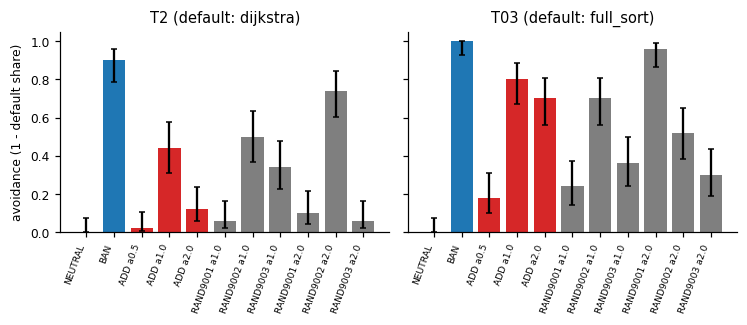

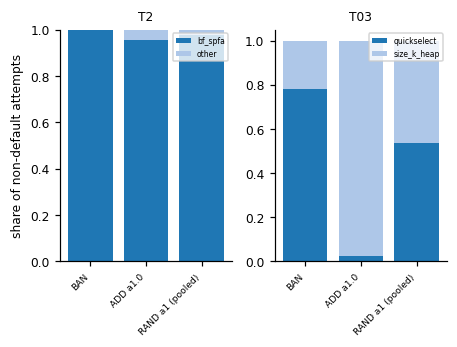

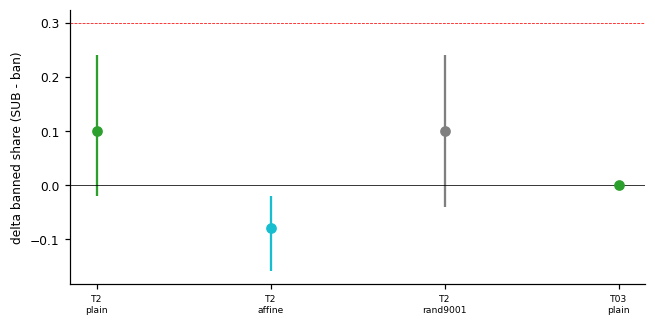

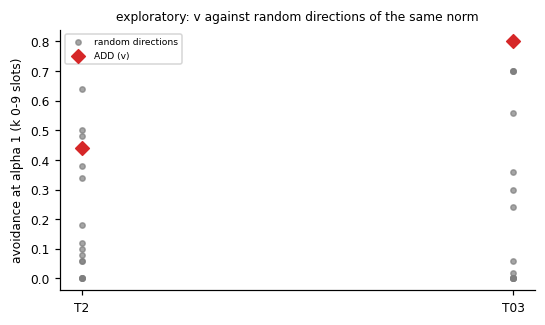

12:52:58|INFO   |C2d on 2500 labelled programs, tasks ['T2', 'T03']: verdict DISCONFIRMED; figures ['fig1_avoidance_by_arm', 'fig2_landing_composition', 'fig3_subtract', 'fig9_random_distribution']


analyze stage (C2d) finished in 0.5 s


In [16]:
t0 = time.time()
logger.catch(reraise=True)(main)()
print(f"analyze stage (C2d) finished in {time.time() - t0:.1f} s")

## 7. Results

### Key numbers, demo against the full run

This cell reads back the `results/c2d.json` that `run_all()` just wrote. It sets each arm's avoidance beside the full
run's value. The full-run summary is stored in the demo data's metadata (`metadata.c2d` and
`metadata.exploratory_random_distribution`), with the same keys as in the artifact's `method_out.json`.

How closely the two columns should match depends on the arm:
- **Must match exactly:** every random-direction arm, ADD α = 0.5 / 2 and SUB_affine / SUB_rand9001. The full run
  sampled these only on the demo's slots k = 0–9.
- **Differ slightly:** BAN, NEUTRAL, SUB_plain and ADD α = 1 (marked `*`). The full run also sampled them on
  k = 10–19.
- **Identical to the full run:** the ADD-versus-random McNemar tests and the exploratory distribution, since both
  are defined on k = 0–9.

In [17]:
c2d = read_json(RESULTS_DIR / "c2d.json")  # written by run_all() above
ref = data["metadata"]                      # full-run summary (same keys as the artifact's method_out.json metadata)


def f2(x, w=5):
    return f"{'n/a':>{w}}" if x is None else f"{x:{w}.2f}"


def fs(x):
    return "n/a" if x is None else f"{x:+.3f}"


def ci2(c, sign=""):
    return "n/a" if not c or c[0] is None else f"[{c[0]:{sign}.2f}, {c[1]:{sign}.2f}]"


ARM_ORDER = ["NEUTRAL", "BAN", "ADD_a0.5", "ADD_a1.0", "ADD_a2.0", "RAND9001_a1.0", "RAND9002_a1.0", "RAND9003_a1.0",
             "RAND9001_a2.0", "RAND9002_a2.0", "RAND9003_a2.0", "SUB_plain", "SUB_affine", "SUB_rand9001"]
K0_19_IN_FULL_RUN = ("NEUTRAL", "BAN", "ADD_a1.0", "SUB_plain")  # the full run also sampled these on k 10-19
rc, ps = ref["c2d"], c2d["pooled_subtract"]
print(f"C2d verdict            demo: {c2d['verdict']:<16} full run: {rc['verdict']}")
print(f"ADD passes             demo: {c2d['n_add_pass']} of {len(c2d['denominator_tasks'])} gated tasks   "
      f"full run: {rc['n_add_pass']} of {len(rc['denominator_tasks'])} gated tasks {rc['denominator_tasks']}")
print(f"within random range    demo: {c2d['tasks_add_within_random_range']}   full run: {rc['within_random_range']}")
print(f"pooled SUBTRACT delta  demo: {fs(ps['delta'])} {ci2(ps.get('ci95_task_bootstrap'), '+')} over {ps['tasks']}   "
      f"full run: {fs(rc['pooled_subtract']['delta'])} {ci2(rc['pooled_subtract'].get('ci95_task_bootstrap'), '+')}"
      f" over {rc['pooled_subtract']['tasks']}")

for t, v in c2d["per_task"].items():
    A, full, g = v["arms"], rc["per_task_add"][t]["avoidance"], v["event_gate"]
    print(f"\n=== {t}: default '{DEFAULT[t]}' | event gate {'PASS' if g['pass'] else 'fail'} "
          f"(BAN avoidance {f2(g['ban_avoidance'], 4)}, {g['ban_n_nonbanned']} non-default programs) ===")
    print(f"  {'arm':<15}{'n':>3}{'avoid':>7}  {'95% CI':<13}{'full run':>9}   landing of the non-default programs")
    for a in [a for a in ARM_ORDER if a in A]:
        s = A[a]
        mark = "*" if a in K0_19_IN_FULL_RUN else " "
        print(f"  {a:<15}{s['n']:>3}{f2(s['avoidance'], 7)}  {ci2(s['avoidance_ci95']):<13}{f2(full.get(a), 8)}{mark}"
              f"   {s['landing']}")
    print("  ADD vs RAND on the same CRN slots (one-sided exact McNemar, Holm over the 6 tests):")
    for x in v["add_vs_rand"]:
        print(f"    alpha {x['alpha']}: ADD {f2(x['add_avoid'], 4)} vs RAND{x['seed']} {f2(x['rand_avoid'], 4)}"
              f"   n10 {x['n10']:>2}  n01 {x['n01']:>2}   p_holm {x['p_holm']:.4f}")
    print(f"  -> ADD passes: {v['add_pass']} | ADD above every random control (alpha 1, 2): "
          f"{v['add_above_max_rand']} | within the random range: {v['add_within_random_range']}")
    for arm, s in v["subtract"].items():
        print(f"  SUBTRACT {arm:<13} delta banned share {fs(s['delta_banned_share'])}  95% CI {ci2(s['ci95'], '+')}"
              f"  ({s['n_pairs']} paired slots)")
    js, fc = v.get("js_add_vs_ban") or {}, v.get("forecast") or {}
    if js.get("null_q95") is not None:
        print(f"  landing: JS(ADD a{fc['best_alpha']}, BAN) = {js['js']:.3f} bits vs permutation q95 {js['null_q95']:.3f}"
              f" (p = {js['p']:.3f}); committed forecast '{fc['forecast_modal']}', ban modal '{fc['ban_modal']}'"
              f" -> hit: {fc['hit']}")
print("\n* full-run value over slots k 0-19; every other full-run value uses the same slots k 0-9 as the demo")

print("\nExploratory: ADD (v) at alpha 1 among every random direction at alpha 1 (slots k 0-9)")
for t, v in c2d["exploratory_random_distribution"].items():
    r = ref["exploratory_random_distribution"].get(t, {})
    same = (set(v["random_avoidance"]) == set(r.get("random_avoidance", {}))
            and all(abs(v["random_avoidance"][a] - r["random_avoidance"][a]) < 1e-12 for a in v["random_avoidance"])
            and abs(v["add_avoidance_k0_9"] - r.get("add_avoidance_k0_9", float("nan"))) < 1e-12)
    print(f"  {t}: ADD {v['add_avoidance_k0_9']:.2f} vs {v['n_random']} random directions (mean {v['random_mean']:.2f},"
          f" q90 {v['random_q90']:.2f}, max {max(v['random_avoidance'].values()):.2f}) -> percentile"
          f" {100 * v['add_percentile_among_random']:.0f}; identical to the full run: {same}")

C2d verdict            demo: DISCONFIRMED     full run: DISCONFIRMED
ADD passes             demo: 0 of 2 gated tasks   full run: 0 of 5 gated tasks ['T2', 'T1', 'T03', 'T06', 'T05']
within random range    demo: ['T2']   full run: ['T2', 'T1', 'T04', 'T06', 'T05']
pooled SUBTRACT delta  demo: +0.050 [+0.00, +0.10] over ['T2', 'T03']   full run: -0.026 [-0.07, +0.03] over ['T2', 'T1', 'T03', 'T06', 'T05']

=== T2: default 'dijkstra' | event gate PASS (BAN avoidance 0.90, 45 non-default programs) ===
  arm              n  avoid  95% CI        full run   landing of the non-default programs
  NEUTRAL         50   0.00  [0.00, 0.07]     0.00*   {}
  BAN             50   0.90  [0.79, 0.96]     0.88*   {'bf_spfa': 45}
  ADD_a0.5        50   0.02  [0.00, 0.10]     0.02    {'bf_spfa': 1}
  ADD_a1.0        50   0.44  [0.31, 0.58]     0.35*   {'bf_spfa': 21, 'other': 1}
  ADD_a2.0        50   0.12  [0.06, 0.24]     0.12    {'bf_spfa': 5, 'other': 1}
  RAND9001_a1.0   50   0.06  [0.02, 0.16]     0.

### What every arm wrote on every CRN slot, and the paired evidence behind each test

The **top figure** is the raw data of C2d:
- each row is one CRN slot (template W1–W5 × k);
- each column is one arm;
- each cell is coloured by the algorithm the program implements, with the default in grey;
- `x` marks a program that failed the task's tests.

Reading across a row compares arms that ran on the same random numbers, which is the comparison CRN makes possible.

The **bottom figure** shows the discordant slots that each ADD-versus-random McNemar test counts:
- n10: ADD avoided the default and the random control did not;
- n01: the reverse;
- the Holm-corrected p-value is printed above each pair.

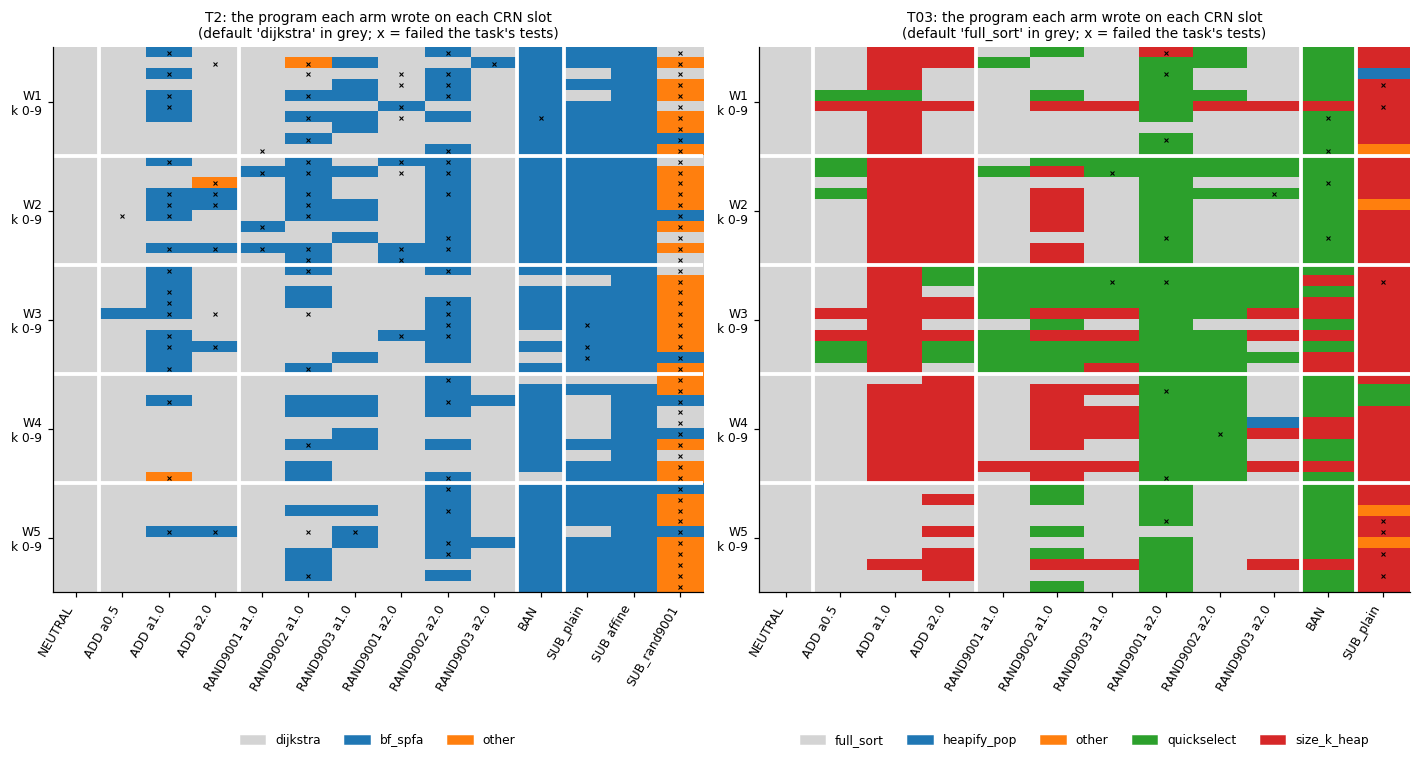

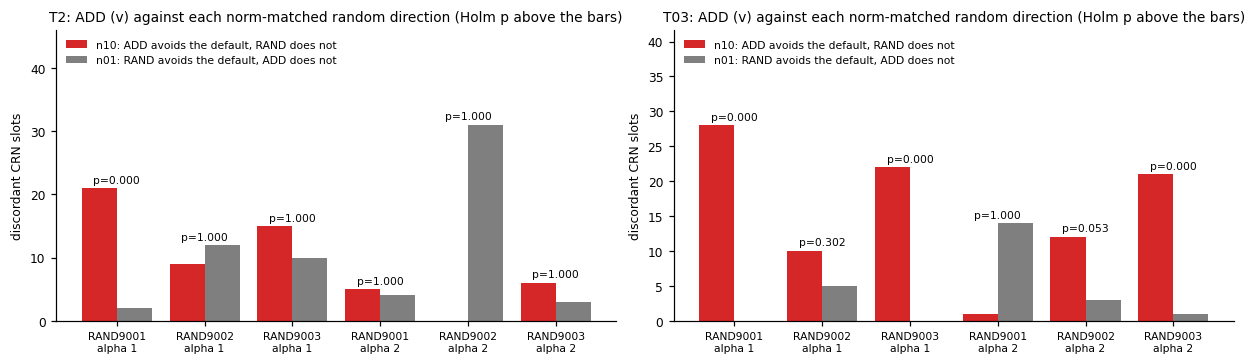

In [18]:
rows = merged()
MAP_ARMS = ["NEUTRAL", "ADD_a0.5", "ADD_a1.0", "ADD_a2.0", "RAND9001_a1.0", "RAND9002_a1.0", "RAND9003_a1.0",
            "RAND9001_a2.0", "RAND9002_a2.0", "RAND9003_a2.0", "BAN", "SUB_plain", "SUB_affine", "SUB_rand9001"]
tasks = [t for t in SAMPLED_TASKS if t in c2d["per_task"]]

# (a) slot x arm map of the algorithm each program implements
fig, axes = plt.subplots(1, len(tasks), figsize=(6.4 * len(tasks), 6.8), squeeze=False, layout="constrained")
for ax, t in zip(axes[0], tasks):
    R = [r for r in rows if r["task"] == t]
    arms = [a for a in MAP_ARMS if any(r["arm"] == a for r in R)]
    slots = sorted({(r["template"], int(r["sample_id"])) for r in R})
    labs = [DEFAULT[t]] + sorted({r["label"] for r in R if r["arm"] in arms} - {DEFAULT[t]})
    cols = ["#d4d4d4"] + [plt.get_cmap("tab10")(i) for i in range(len(labs) - 1)]
    cell = {(r["template"], int(r["sample_id"]), r["arm"]): r for r in R}
    grid = np.full((len(slots), len(arms)), np.nan)
    fail_xy = []
    for i, (w, k) in enumerate(slots):
        for j, a in enumerate(arms):
            r = cell.get((w, k, a))
            if r is not None:
                grid[i, j] = labs.index(r["label"])
                if not r["passed"]:
                    fail_xy.append((j, i))
    ax.imshow(np.ma.masked_invalid(grid), cmap=ListedColormap(cols), vmin=-0.5, vmax=len(labs) - 0.5,
              aspect="auto", interpolation="nearest")
    if fail_xy:
        ax.plot(*zip(*fail_xy), "x", color="black", ms=3, mew=0.7)
    ws = [w for w, _ in slots]
    for i in range(1, len(slots)):  # white lines between templates
        if ws[i] != ws[i - 1]:
            ax.axhline(i - 0.5, color="white", lw=2.5)
    fam = ["RAND" if a.startswith("RAND") else a.split("_")[0] for a in arms]
    for j in range(1, len(arms)):  # ... and between arm families (NEUTRAL | ADD | RAND | BAN | SUB)
        if fam[j] != fam[j - 1]:
            ax.axvline(j - 0.5, color="white", lw=2.5)
    ax.set_xlim(-0.5, len(arms) - 0.5)
    ax.set_ylim(len(slots) - 0.5, -0.5)
    centres = {w: np.mean([i for i, ww in enumerate(ws) if ww == w]) for w in sorted(set(ws))}
    ax.set_yticks(list(centres.values()))
    ax.set_yticklabels([f"{w}\nk 0-{SLOTS_PER_TEMPLATE - 1}" for w in centres], fontsize=8)
    ax.set_xticks(range(len(arms)))
    ax.set_xticklabels([a.replace("_a", " a") for a in arms], rotation=60, ha="right", fontsize=8)
    ax.set_title(f"{t}: the program each arm wrote on each CRN slot\n(default '{DEFAULT[t]}' in grey; "
                 f"x = failed the task's tests)", fontsize=9)
    ax.legend(handles=[Patch(color=c, label=l) for c, l in zip(cols, labs)], loc="upper center",
              bbox_to_anchor=(0.5, -0.24), ncol=min(len(labs), 5), fontsize=8, frameon=False)
plt.show()

# (b) the discordant CRN slots behind each one-sided McNemar test of ADD against a frozen random control
fig, axes = plt.subplots(1, len(tasks), figsize=(5.6 * len(tasks), 3.2), squeeze=False, layout="constrained")
for ax, t in zip(axes[0], tasks):
    tests = c2d["per_task"][t]["add_vs_rand"]
    if not tests:
        continue
    xs = np.arange(len(tests))
    ax.bar(xs - 0.2, [x["n10"] for x in tests], 0.4, color="#d62728", label="n10: ADD avoids the default, RAND does not")
    ax.bar(xs + 0.2, [x["n01"] for x in tests], 0.4, color="#7f7f7f", label="n01: RAND avoids the default, ADD does not")
    top = max(max(x["n10"], x["n01"]) for x in tests)
    for xi, x in zip(xs, tests):
        ax.text(xi, max(x["n10"], x["n01"]) + 0.02 * top + 0.2, f"p={x['p_holm']:.3f}", ha="center", fontsize=7)
    ax.set_ylim(0, 1.45 * top + 1)
    ax.set_xticks(xs)
    ax.set_xticklabels([f"RAND{x['seed']}\nalpha {x['alpha']:g}" for x in tests], fontsize=7)
    ax.set_ylabel("discordant CRN slots")
    ax.set_title(f"{t}: ADD (v) against each norm-matched random direction (Holm p above the bars)", fontsize=9)
    ax.legend(fontsize=7, loc="upper left", frameon=False)
plt.show()

## Reading the results

On these 100 CRN slots the demo reproduces the full run's C2d conclusion:

- **T2 (Dijkstra).** The named ban moves 90% of programs off Dijkstra, all of them to Bellman-Ford/SPFA. Adding `v`
  to the neutral twin (ADD α = 1) moves 44%, also mostly to Bellman-Ford/SPFA. But random directions of the same
  norm move 6%, 50% and 34%, and at α = 2 one of them moves 74%. ADD significantly beats only one of the three
  controls, so T2 is **within the random range**. Among all 15 random directions, `v` sits at the 80th percentile.
- **T03 (full sort).** ADD α = 1 (80%) is above all three random controls (24%, 70%, 36%), but only two of the three
  McNemar tests survive Holm. It also lands on a **size-k heap**, while the ban lands on **quickselect**: the JS
  divergence of the two landings is about 0.5 bits, against a permutation q95 of about 0.03. So `v` is the
  strongest push among all 15 random directions on T03, yet it does not reproduce the ban.
- **SUBTRACT.** Projecting `v` out of the ban prompt does not restore the default: Δ = +0.10 on T2 with a CI that
  includes 0, and Δ = 0 on T03, where no banned program is left to restore. Both are far below the 0.3 the rule
  requires. The demo's pooled Δ (≈ +0.05 over T2 and T03) differs from the full run's −0.026 because the full run
  pools 5 gated tasks over 100 slots each.
- **Verdict: DISCONFIRMED.** The full run gives the same verdict: ADD passes on 0 of 5 gated tasks, it is within the
  random range on 5 of 6 tasks, and the pooled SUBTRACT Δ = −0.026 [−0.07, 0.03].

Put plainly: the shared component of the ban displacement is no more of a "prohibition" than a random push of the
same size, and removing it does not lift the ban.

**Scaling back to the full experiment.** The analysis parameters in the configuration cell already have their
original values. The full analysis needs the artifact's complete repository and its commands in
`reproducibility.md`:

```
method.py prompts → gpu1 → label → commit2 → gpu2 → c2e → zerog → analyze
```

That covers all 6 tasks, slots k 0–19, and the C2e, C2f, 0g, 5a and 5c analyses. It requires a GPU with FP8
support (≥ 16 GB, compute capability ≥ 8.9) and about 3.5 GPU-hours. Given the stored `data/labels.jsonl`,
`method.py analyze` alone reruns every CPU analysis.